# Tarea 2 — Inteligencia Artificial



- Integrantes: Andrés Hormazabal, Héctor Vines.
- Profesor: Johan Fuentes. 
- Ayudantes: Dante Libiot, Miguel Pereira, Matias Vasquez.
- URL del dataset utilizado para la pregunta 1: https://www.kaggle.com/datasets/bahramjannesarr/goodreads-book-datasets-10m

- URL del dataset utilizado para la pregunta 2: https://www.kaggle.com/datasets/fedesoriano/stellar-classification-dataset-sdss17


In [16]:
import os
import kagglehub
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np


In [ ]:
# Codigo para descargar los datasets de manera online

path_sdss_dir = kagglehub.dataset_download("fedesoriano/stellar-classification-dataset-sdss17")
sdss_file = os.path.join(path_sdss_dir, "star_classification.csv")
df_sdss = pd.read_csv(sdss_file)
print("Dataset SDSS17 cargado correctamente.")

# 2. Descargar y cargar Goodreads
path_goodreads_dir = kagglehub.dataset_download("bahramjannesarr/goodreads-book-datasets-10m")
goodreads_file = os.path.join(path_goodreads_dir, "book1-100k.csv")
df_goodreads = pd.read_csv(goodreads_file)
print("Dataset Goodreads cargado correctamente.")

/Users/andres/Desktop/tarea2IA/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 6.89M/6.89M [00:01<00:00, 6.04MB/s]

Extracting files...


Dataset SDSS17 cargado correctamente.


100%|██████████| 460M/460M [00:24<00:00, 19.6MB/s] 

Extracting files...


Dataset Goodreads cargado correctamente.


In [ ]:
#Codigo para importar los datasets desde el proyecto

os.makedirs("data/raw", exist_ok=True)

path_sdss = "data/raw/star_classification.csv"
path_goodreads = "data/raw/book1-100k.csv"


if os.path.exists(path_sdss):
    df_sdss = pd.read_csv(path_sdss)
    print("Dataset SDSS17 cargado correctamente.")
else:
    print(f"Error: Coloca el archivo descargado en la ruta '{path_sdss}'")

if os.path.exists(path_goodreads):
    df_goodreads = pd.read_csv(path_goodreads)
    print(f"\nDataset Goodreads cargado correctamente.")
else:
    print("Error")


Dataset SDSS17 cargado correctamente.

Dataset Goodreads cargado correctamente.


## Parte 1 — Algoritmos de aprendizaje supervizado

El dataset elegido fue el book1-100k.csv por la cantidad de filas y columnas que tiene, ya que cumple con los requerimientos de la tarea. Además, el área de la literatura es interesante para nosotros, y poder usar un dataset de este dominio son interesa.


### 1.0 Dataset y variables

| Símbolo | Columna | Descripción | Tipo |
|---|---|---|---|
| A | ID |  |  |
| B | Name | |  |
| C | RatingDist1 | Rarting 1 Star |  |
| D | pagesNumber | |  |
| E | RatingDist4 | Rarting 4 Star |  |
| F | RatingDistTotal | Total number of Rating |  |
| G | PublishMonth |  |  |
| H | PublishDay |  |  |
| I | Publisher |  |   |
| J | CountsOfReview |  |  |
| K | PublishYear |  |  |
| L | Language |  |  |
| M | Authors |  |  |
| N | Rating | Average of Rating |  |
| O | RatingDist2 | Rarting 2 Star |  |
| P | RatingDist5 | Rarting 5 Star |  |
| Q | ISBN |  |  |
| R | RatingDist3 | Rarting 3 Star |  |

La variable continua $Y_1$ elegida es 
La variable discreta binaria $Y_2$ elegida es 



In [15]:
df_goodreads.info()
df_goodreads.describe()

#Conteno de nulos por columna 
print("\nConteo de nulos por columna:")
print(df_goodreads.isnull().sum()[df_goodreads.isnull().sum() > 0])


<class 'pandas.DataFrame'>
RangeIndex: 58292 entries, 0 to 58291
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Id               58292 non-null  int64  
 1   Name             58292 non-null  str    
 2   RatingDist1      58292 non-null  str    
 3   pagesNumber      58292 non-null  int64  
 4   RatingDist4      58292 non-null  str    
 5   RatingDistTotal  58292 non-null  str    
 6   PublishMonth     58292 non-null  int64  
 7   PublishDay       58292 non-null  int64  
 8   Publisher        57798 non-null  str    
 9   CountsOfReview   58292 non-null  int64  
 10  PublishYear      58292 non-null  int64  
 11  Language         20294 non-null  str    
 12  Authors          58292 non-null  str    
 13  Rating           58292 non-null  float64
 14  RatingDist2      58292 non-null  str    
 15  RatingDist5      58292 non-null  str    
 16  ISBN             57746 non-null  str    
 17  RatingDist3      58292 

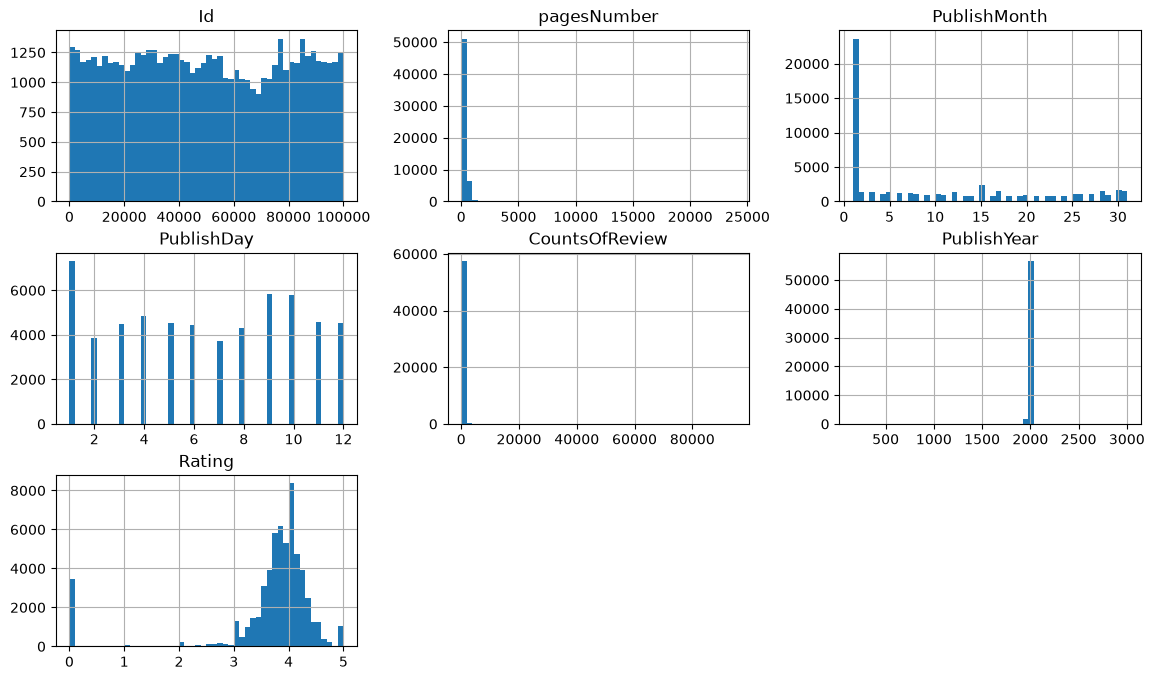

In [12]:

df_goodreads.hist(bins=50, figsize=(14,8))
plt.show()

### Variables Predictorias 



### Entrenamiento




In [ ]:


def shuffle_and_split_data(data, test_ratio):
    shuffle_indices = np.random.permutation(len(df_goodreads))
    test_set_size = int(len(df_goodreads)*test_ratio)
    test_indices = shuffle_indices[:test_set_size]
    train_indices = shuffle_indices[test_set_size:]
    return df_goodreads.iloc[train_indices], df_goodreads.iloc[test_indices]

print(f"\n{shuffle_and_split_data(df_goodreads, 0.7)}")



(          Id                                               Name RatingDist1  \
25127  41723              Wildcats Version 3.0: Full Disclosure         1:2   
50473  86974                  Refugee Policy in Sudan 1967-1984         1:0   
34688  58481  Walking the Flatlands: The Rural Landscape of ...         1:0   
39242  67268                     Emil Nolde: Unpainted Pictures         1:0   
27630  46194                                     What's Heaven?         1:7   
...      ...                                                ...         ...   
53504  91933            Dracula: Level 5: 5,000 Word Vocabulary         1:0   
8358   13734  Zombie Powder: The Man With the Black Hand (Zo...        1:24   
16333  27427                             The Eclogues of Virgil        1:46   
7385   12204                 The Road Not Taken and Other Poems       1:322   
24558  40815                      The Alligator Snapping Turtle         1:0   

       pagesNumber RatingDist4 RatingDistTotal  P

### Validación

### Prueba
